In [2]:
from dotenv import load_dotenv
import os   
from langchain.chat_models import init_chat_model
load_dotenv()  # Load environment variables from .env file
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")
# model = init_chat_model("groq:openai/gpt-oss-120b")
# model


In [3]:
import glob
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_google_genai import GoogleGenerativeAIEmbeddings

DOCS_DIR  = "sample_docs"
INDEX_DIR = "faiss_index"

def load_and_split(docs_dir):
    chunks = []
    for path in glob.glob(os.path.join(docs_dir, "*.pdf")):
        with open(path, "r", encoding="utf-8") as f:
            text = f.read()
        source = os.path.basename(path)
        paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
        current = ""
        for para in paragraphs:
            if len(current) + len(para) + 2 <= 500:
                current = (current + "\n\n" + para).strip()
            else:
                if current:
                    chunks.append(Document(page_content=current, metadata={"source": source}))
                current = para
        if current:
            chunks.append(Document(page_content=current, metadata={"source": source}))
    return chunks

chunks = load_and_split(DOCS_DIR)
print(f"{len(chunks)} chunks of available documents ({DOCS_DIR}/DSA_Manual).")

C:\Users\acer\AppData\Local\Temp\ipykernel_29192\563186315.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


7 chunks of available documents (sample_docs/DSA_Manual).


In [4]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

# Uses a free, lightweight local model (~80MB download on first run)
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vectorstore = FAISS.from_documents(chunks, embeddings)
vectorstore.save_local(INDEX_DIR)
print(f"Index saved to {INDEX_DIR}/")

c:\Users\acer\Desktop\mistral\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4119.79it/s]


Index saved to faiss_index/


In [5]:
from langchain_core.tools import tool

import ast
import json
import operator
import os
import re
import requests
import wikipedia
from datetime import datetime
from typing import List, Literal
from langchain_core.tools import tool
from langchain_tavily import TavilySearch

# ==========================================
# 1. CALCULATOR TOOL
# ==========================================
@tool
def calculator(expression: str) -> str:
    """
    Calculate mathematical expressions accurately. 
    Input must be a math string like '45 * 12 + 100' or '2 ** 10'.
    """
    allowed_ops = {
        ast.Add: operator.add, ast.Sub: operator.sub,
        ast.Mult: operator.mul, ast.Div: operator.truediv,
        ast.Pow: operator.pow, ast.USub: operator.neg,
    }
    def _eval(node):
        if isinstance(node, ast.Constant):
            return node.value
        elif isinstance(node, ast.BinOp):
            return allowed_ops[type(node.op)](_eval(node.left), _eval(node.right))
        elif isinstance(node, ast.UnaryOp):
            return allowed_ops[type(node.op)](_eval(node.operand))
        raise ValueError("Unsupported operation")

    try:
        node = ast.parse(expression, mode="eval").body
        return f"Result: {_eval(node)}"
    except Exception as e:
        return f"Math Error: {str(e)}"


# ==========================================
# 2. INTENT AND KEYWORD EXTRACTOR TOOL
# ==========================================
@tool
def extract_intent_and_keywords(
    user_query: str,
    intent: Literal["question", "complaint", "booking", "greeting", "search", "calculation", "other"],
    keywords: List[str]
) -> str:
    """
    Analyze a user query to log its primary intent and extract important keywords.
    The LLM automatically identifies the intent and keywords and passes them here.
    """
    payload = {
        "original_query": user_query,
        "detected_intent": intent,
        "extracted_keywords": keywords,
    }
    return json.dumps(payload, indent=2)


# ==========================================
# 3. GREETING TOOL
# ==========================================
@tool
def greet_user(name: str = "Friend") -> str:
    """
    Generate a time-appropriate personalized greeting when the user says hello, hi, or namaste.
    """
    hour = datetime.now().hour
    if hour < 12:
        time_greeting = "Good morning"
    elif hour < 17:
        time_greeting = "Good afternoon"
    else:
        time_greeting = "Good evening"
        
    return f"Namaste and {time_greeting}, {name}! How can I help you today?"


# ==========================================
# 4. TAVILY WEB SEARCH TOOL
# ==========================================
@tool
def tavily_web_search(query: str) -> str:
    """
    Search the web using Tavily for real-time news, current events, and facts.
    Requires TAVILY_API_KEY set in your environment variables.
    """
    if not os.environ.get("TAVILY_API_KEY"):
        return "Error: TAVILY_API_KEY is not set in environment variables."
    try:
        search = TavilySearch(max_results=3)
        results = search.invoke({"query": query})
        return str(results)
    except Exception as e:
        return f"Tavily search error: {str(e)}"


# ==========================================
# 5. CURRENT DATE & TIME TOOL
# ==========================================
@tool
def get_current_datetime() -> str:
    """
    Get the exact current system date, day of the week, and time.
    Use this whenever the user asks 'what day is today' or 'what time is it'.
    """
    now = datetime.now()
    return now.strftime("Date: %Y-%m-%d | Day: %A | Time: %H:%M:%S")


# ==========================================
# 6. LIVE WEATHER TOOL
# ==========================================
@tool
def get_live_weather(city: str) -> str:
    """
    Fetch the current live weather condition and temperature for any city.
    """
    try:
        res = requests.get(f"https://wttr.in/{city}?format=3", timeout=5)
        if res.status_code == 200:
            return res.text.strip()
        return f"Could not fetch weather for {city}."
    except Exception as e:
        return f"Weather API error: {str(e)}"


# ==========================================
# 7. WIKIPEDIA SUMMARY TOOL
# ==========================================
@tool
def search_wikipedia(topic: str) -> str:
    """
    Fetch a short encyclopedia summary about historical events, famous people, or science topics.
    """
    try:
        return wikipedia.summary(topic, sentences=3)
    except wikipedia.exceptions.DisambiguationError as e:
        return f"Topic is ambiguous. Try one of these: {e.options[:5]}"
    except Exception as e:
        return f"Wikipedia lookup failed: {str(e)}"


# ==========================================
# 8. CURRENCY CONVERTER TOOL
# ==========================================
@tool
def convert_currency(amount: float, from_currency: str, to_currency: str) -> str:
    """
    Convert money from one currency code to another (e.g., 'USD' to 'NPR', 'EUR' to 'INR').
    """
    from_curr = from_currency.upper().strip()
    to_curr = to_currency.upper().strip()
    try:
        url = f"https://open.er-api.com/v6/latest/{from_curr}"
        data = requests.get(url, timeout=5).json()
        rate = data["rates"].get(to_curr)
        if not rate:
            return f"Currency code '{to_curr}' not found."
        converted = amount * rate
        return f"{amount} {from_curr} = {converted:.2f} {to_curr} (Rate: {rate})"
    except Exception as e:
        return f"Currency conversion failed: {str(e)}"


# ==========================================
# 9. UNIT CONVERTER TOOL
# ==========================================
@tool
def convert_units(
    value: float, 
    conversion_type: Literal["km_to_miles", "miles_to_km", "kg_to_lbs", "lbs_to_kg", "c_to_f", "f_to_c"]
) -> str:
    """
    Convert common physical units: kilometers/miles, kilograms/pounds, or Celsius/Fahrenheit.
    """
    formulas = {
        "km_to_miles": (value * 0.621371, "miles"),
        "miles_to_km": (value / 0.621371, "km"),
        "kg_to_lbs": (value * 2.20462, "lbs"),
        "lbs_to_kg": (value / 2.20462, "kg"),
        "c_to_f": ((value * 9/5) + 32, "°F"),
        "f_to_c": ((value - 32) * 5/9, "°C"),
    }
    result, unit = formulas[conversion_type]
    return f"{result:.2f} {unit}"


# ==========================================
# 10. TEXT & WORD ANALYZER TOOL
# ==========================================
@tool
def analyze_text_stats(text: str) -> str:
    """
    Count exact characters, words, and sentences in a given piece of text.
    """
    char_count = len(text)
    word_count = len(text.split())
    sentence_count = max(1, text.count(".") + text.count("!") + text.count("?"))
    return f"Words: {word_count} | Characters: {char_count} | Sentences: {sentence_count}"


# ==========================================
# 11. EMAIL & PHONE EXTRACTOR TOOL
# ==========================================
@tool
def extract_contacts_from_text(text: str) -> str:
    """
    Extract all email addresses and phone numbers from a messy paragraph of text.
    """
    emails = re.findall(r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}", text)
    phones = re.findall(r"\+?\d[\d\s\-]{7,14}\d", text)
    return json.dumps({"emails": emails, "phone_numbers": phones})


# ==========================================
# 12. SAVE NOTE TO FILE TOOL
# ==========================================
@tool
def save_note(filename: str, content: str) -> str:
    """
    Save important notes, summaries, or outputs into a local text file.
    """
    safe_name = os.path.basename(filename)
    with open(safe_name, "w", encoding="utf-8") as f:
        f.write(content)
    return f"Saved note successfully to '{safe_name}'."

@tool
def search_docs(query: str) -> str:
    """Search the knowledge base for information about DSA (Data structure and Algorithms) concepts,
    Arrays, Linked Lists, stacks, queues,recursion,trees,graphs,searching algorithms, sorting algorithms, hashing and related topics."""
    embeddings  = HuggingFaceEmbeddings(model_name ="sentence-transformers/all-MiniLM-L6-v2")
    vectorstore = FAISS.load_local(INDEX_DIR, embeddings, allow_dangerous_deserialization=True)
    docs = vectorstore.as_retriever(search_kwargs={"k": 3}).invoke(query)
    return "\n\n---\n\n".join(doc.page_content for doc in docs)

In [6]:
tools = [
    calculator,
    extract_intent_and_keywords,
    greet_user,
    tavily_web_search,
    get_current_datetime,
    get_live_weather,
    search_wikipedia,
    convert_currency,
    convert_units,
    analyze_text_stats,
    extract_contacts_from_text,
    save_note,
]
tools_by_name = {t.name: t for t in tools}

In [7]:
model = init_chat_model("groq:openai/gpt-oss-120b",temperature=0)

model_with_tools = model.bind_tools(tools)


In [8]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage

class MessagesState(TypedDict):
    messages:  Annotated[list[AnyMessage], operator.add]
    llm_calls: int

In [9]:
from langchain_core.messages import SystemMessage, ToolMessage

def llm_call(state: MessagesState) -> dict:
    response = model_with_tools.invoke(
        [SystemMessage(content=(
            "You are a helpful assistant that can perform arithmetic "
            "and answer questions about DSA (Data Structure and Algorithms) concepts. "
            "You are a helpful AI assistant equipped with 12 specialized tools:\n"
    "- Use `calculator` for arithmetic and math expressions.\n"
    "- Use `extract_intent_and_keywords` when asked to classify intent or extract keywords.\n"
    "- Use `greet_user` when the user greets you or introduces themselves.\n"
    "- Use `tavily_web_search` for live news and real-time web queries.\n"
    "- Use `get_current_datetime` for the current date, day, or time.\n"
    "- Use `get_live_weather` for current city weather conditions.\n"
    "- Use `search_wikipedia` for encyclopedic or historical summaries.\n"
    "- Use `convert_currency` and `convert_units` for currency and unit conversions.\n"
    "- Use `analyze_text_stats` and `extract_contacts_from_text` for text analysis.\n"
    "- Use `save_note` when asked to save outputs to a local file."

            "Use search_docs for DSA questions."
        ))] + state["messages"]
    )
    return {
        "messages":  [response],
        "llm_calls": state.get("llm_calls", 0) + 1,
    }


def tool_node(state: MessagesState) -> dict:
    results = []
    for tool_call in state["messages"][-1].tool_calls:
        t= tools_by_name[tool_call["name"]]
        observation = t.invoke(tool_call["args"])
        results.append(ToolMessage(content=str(observation), tool_call_id=tool_call["id"]))
    return {"messages": results}

In [10]:
from typing import Literal
from langgraph.graph import END

def should_continue(state: MessagesState) -> Literal["tool_node", "__end__"]:
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tool_node"
    return END

In [11]:

from langgraph.graph import StateGraph, START, END


agent_builder = StateGraph(MessagesState)

agent_builder.add_node("llm_call",  llm_call)
agent_builder.add_node("tool_node", tool_node)


agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges("llm_call", should_continue, ["tool_node", END])
agent_builder.add_edge("tool_node", "llm_call")

agent = agent_builder.compile()

In [12]:
from langchain_core.messages import HumanMessage, AIMessage

def run_agent(question: str):
    print(f"Q: {question}")
    result = agent.invoke({"messages": [HumanMessage(content=question)], "llm_calls": 0})
    for msg in result["messages"]:
        if isinstance(msg, AIMessage) and msg.tool_calls:
            for tc in msg.tool_calls:
                print(f"  tool: {tc['name']}  args: {tc['args']}")
        if isinstance(msg, ToolMessage):
            print(f"  result: {msg.content[:120]}")
    print(f"A: {result['messages'][-1].content}")
    print()

In [13]:
run_agent("What is a binary search tree and how does it work?")

Q: What is a binary search tree and how does it work?
A: **Binary Search Tree (BST) – Overview**

A **binary search tree** is a special kind of binary tree that stores *ordered* data and supports fast lookup, insertion, and deletion. It is widely used in algorithms and data‑structure courses because it provides a good balance between simplicity and efficiency.

---

### 1. Structural Rules

For every node `N` in a BST:

| Condition | Meaning |
|-----------|---------|
| **Left Subtree** | All keys in the left subtree of `N` are **strictly less** than `N.key`. |
| **Right Subtree** | All keys in the right subtree of `N` are **strictly greater** than `N.key`. |
| **Recursion** | Both left and right sub‑trees are themselves binary search trees. |

Because of these rules, an **in‑order traversal** (left → root → right) visits the keys in **sorted (ascending) order**.

---

### 2. Core Operations

| Operation | How it works (high‑level) | Average‑case Complexity | Worst‑case Complexity |
|--

In [14]:
run_agent("who is the prime minister of Nepal?")

Q: who is the prime minister of Nepal?
  tool: tavily_web_search  args: {'query': 'current prime minister of Nepal'}
  result: {'query': 'current prime minister of Nepal', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'ur
A: The current Prime Minister of Nepal is **Balendra Shah**. He has been serving in the role since 27 March 2026.



In [15]:
run_agent('''summarize the following text:K-Means Clustering
Partitions data into k clusters, where each point belongs to the cluster with the
nearest centroid (mean of points in that cluster).
Algorithm: 1. Choose k (number of clusters) and randomly initialize k centroids.
2. Assignment step: assign each point to its nearest centroid. 3. Update step:
recompute each centroid as the mean of all points assigned to it. 4. Repeat steps 2–3
until centroids stop changing (convergence) or a max iteration count is reached.
Choosing k — the Elbow Method: plot the within-cluster sum of squares
(WCSS/inertia) against different values of k; pick the k at the “elbow” point where
the rate of decrease sharply slows.
Limitations:- Must specify k in advance.- Sensitive to initial centroid placement
(can converge to a local optimum) — mitigated by running multiple times with differ
ent initializations (k-means++ improves initialization).- Assumes roughly spherical,
similarly-sized clusters — struggles with irregular cluster shapes.- Sensitive to out
liers (since it uses the mean)''')

Q: summarize the following text:K-Means Clustering
Partitions data into k clusters, where each point belongs to the cluster with the
nearest centroid (mean of points in that cluster).
Algorithm: 1. Choose k (number of clusters) and randomly initialize k centroids.
2. Assignment step: assign each point to its nearest centroid. 3. Update step:
recompute each centroid as the mean of all points assigned to it. 4. Repeat steps 2–3
until centroids stop changing (convergence) or a max iteration count is reached.
Choosing k — the Elbow Method: plot the within-cluster sum of squares
(WCSS/inertia) against different values of k; pick the k at the “elbow” point where
the rate of decrease sharply slows.
Limitations:- Must specify k in advance.- Sensitive to initial centroid placement
(can converge to a local optimum) — mitigated by running multiple times with differ
ent initializations (k-means++ improves initialization).- Assumes roughly spherical,
similarly-sized clusters — struggles with irregu

In [16]:
run_agent("calculate 45 * 12 + 100")

Q: calculate 45 * 12 + 100
  tool: calculator  args: {'expression': '45 * 12 + 100'}
  result: Result: 640
A: The result of \(45 \times 12 + 100\) is **640**.



In [19]:
run_agent("what is the current weather in Bharatpur, Nepal?")

Q: what is the current weather in Bharatpur, Nepal?
  tool: get_live_weather  args: {'city': 'Bharatpur, Nepal'}
  result: Bharatpur, Nepal: ☁️  +23°C
A: Here’s the latest weather for **Bharatpur, Nepal**:

- **Condition:** Cloudy ☁️  
- **Temperature:** **23 °C**  

Let me know if you’d like a forecast, humidity details, or anything else!



In [20]:
run_agent("convert 150 USD to NPR")

Q: convert 150 USD to NPR
  tool: convert_currency  args: {'amount': 150, 'from_currency': 'USD', 'to_currency': 'NPR'}
  result: 150.0 USD = 22869.82 NPR (Rate: 152.465479)
A: Sure!  

**150 USD ≈ 22,869.82 NPR**  

(Conversion rate used: 1 USD ≈ 152.47 NPR)



In [21]:
run_agent("what is the intent of the query 'list the top 5 janajati boys marks in nepali , social, and math ' and extract keywords?")

Q: what is the intent of the query 'list the top 5 janajati boys marks in nepali , social, and math ' and extract keywords?
  tool: extract_intent_and_keywords  args: {'intent': 'search', 'keywords': ['top 5', 'Janajati', 'boys', 'marks', 'Nepali', 'Social', 'Math'], 'user_query': 'list the top 5 janajati boys marks in nepali , social, and math'}
  result: {
  "original_query": "list the top 5 janajati boys marks in nepali , social, and math",
  "detected_intent": "search",

A: **Intent:** search  

**Keywords:** top 5, Janajati, boys, marks, Nepali, Social, Math



In [22]:
run_agent("explain about the datastructure and algorithms in simple terms with examples")

Q: explain about the datastructure and algorithms in simple terms with examples
A: ### What are Data Structures?

A **data structure** is a way of organizing and storing data so that you can use it efficiently.  
Think of it as a container that decides **how** the data is arranged and **what** operations you can perform quickly on it.

| Data Structure | How It Stores Data | Typical Use‑Case (Simple Example) |
|----------------|-------------------|-----------------------------------|
| **Array** | Fixed‑size, contiguous block of memory; elements accessed by index | List of daily temperatures: `temps[0] = 72°F`, `temps[1] = 68°F` |
| **Linked List** | Nodes that hold a value and a pointer to the next node | A train of cars where each car knows the car behind it; easy to add/remove cars at the ends |
| **Stack** | “Last‑In‑First‑Out” (LIFO) – push on top, pop from top | Browser “Back” button: the most recent page you visited is the first you go back to |
| **Queue** | “First‑In‑First‑Out

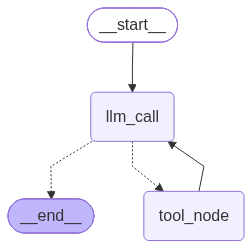

In [18]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))